# 03. Three-Stage Latency Adverse Selection, Market-Making Tournament (AS vs GLFT vs CJP), Square-Root Impact & Survival Analysis

**Repository**: `queue-reactive-book`  
**References**:
- Avellaneda, M., & Stoikov, S. (2008). *High-frequency trading in a limit order book*. **Quantitative Finance**, 8(3), 217-224.
- Guéant, O., Lehalle, C.-A., & Fernandez-Tapia, J. (2013). *Dealing with the inventory risk: a solution to the market making problem*. **Mathematics and Financial Economics**, 7(4), 477-507.
- Cartea, Á., Jaimungal, S., & Penalva, J. (2015). *Algorithmic and High-Frequency Trading*. **Cambridge University Press**.
- Bouchaud, J.-P., Farmer, J. D., & Lillo, F. (2009). *How markets slowly digest changes in supply and demand*. **Handbook of Financial Markets: Dynamics and Evolution**.

---

## Executive Summary

This notebook evaluates multi-agent execution, latency sensitivity, and transaction cost analysis (TCA) using `sim::SimulationSession` (`include/sim/simulation.hpp`):
1. **Three-Stage Latency Adverse Selection Sweep**: We vary total round-trip latency $\Delta t_{\text{lat}} = \Delta t_{\text{md}} + \Delta t_{\text{dec}} + \Delta t_{\text{oe}}$ from `0 ns` (colocated ideal) to `2,000,000 ns` (`2 ms`) across Avellaneda-Stoikov (2008), GLFT (2013), and CJP (2015) market makers, measuring `ThreeRiskTriplet` (`maker_adversity_x2`, `taker_adversity_x2`, `queue_risk_x2`) without cross-axis netting.
2. **Multi-Agent Market-Making Tournament & Game-Theoretic Exploitability**: We pit 5 concurrent agents (`AvellanedaStoikov`, `GLFT`, `CJP`, `PassiveMaker`, and `LatencyTaker`) in the same L3 book and evaluate `probe_exploitability` (`is_equilibrium_certificate == false` invariant).
3. **Execution Schedule Comparison (`TWAP` vs `VWAP` vs `POV`) & Square-Root Impact Law**: We compare parent-order execution schedules and verify the square-root impact law $\Delta p(\phi) = Y \sigma \sqrt{\phi}$ via `sim::ImpactScore`.


In [1]:
import sys
import subprocess
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(pathlib.Path.cwd()))
import qrlob_notebook_utils as qru

qru.apply_publication_style()


## 1. Three-Stage Latency Sweep (`md_delay_ns` + `decision_delay_ns` + `oe_delay_ns`)

We sweep round-trip latency across 8 tiers (`0 ns` to `2,000,000 ns`) for three structural market-making models:
- **Avellaneda-Stoikov (2008)**: $r(s, q, \tau) = s - q \gamma \sigma^2 \tau$
- **GLFT (2013) Infinite-Horizon Asymptotic**: Inventory-clipped exponential spread skew $c_{\text{GLFT}} = \sqrt{\frac{\sigma^2 \gamma}{2 A k}(1 + \gamma/k)^{1 + k/\gamma}}$
- **Cartea-Jaimungal-Penalva (2015) OFI-Alpha Skew**: Incorporates short-term Order Flow Imbalance drift $\alpha_{\text{OFI}}$ and running inventory penalty $\phi q$


In [2]:
lat_grid = [0, 250, 1000, 5000, 25000, 100000, 500000, 2000000]
df_as = qru.run_latency_sweep_dataframe(agent_kind=0, latencies_ns=lat_grid, events_per_run=5000, seed=4242)
df_glft = qru.run_latency_sweep_dataframe(agent_kind=1, latencies_ns=lat_grid, events_per_run=5000, seed=4242)
df_cjp = qru.run_latency_sweep_dataframe(agent_kind=2, latencies_ns=lat_grid, events_per_run=5000, seed=4242)

print("Avellaneda-Stoikov Latency Sweep:")
display(df_as[["latency_ns", "quotes_emitted", "passive_fills", "final_inventory",
               "mark_to_mid_pnl", "maker_adversity_x2", "queue_risk_x2"]])


Avellaneda-Stoikov Latency Sweep:


,latency_ns,quotes_emitted,passive_fills,final_inventory,mark_to_mid_pnl,maker_adversity_x2,queue_risk_x2
0,0,4938,5,0,0.0,0,110
1,250,4938,19,0,-10.0,20,304
2,1000,4938,19,0,-10.0,20,304
3,5000,4938,19,0,-10.0,20,304
4,25000,4938,19,0,-10.0,20,304
5,100000,4938,19,0,-10.0,18,304
6,500000,4938,16,0,-10.0,11,268
7,2000000,4938,5,0,0.0,3,62


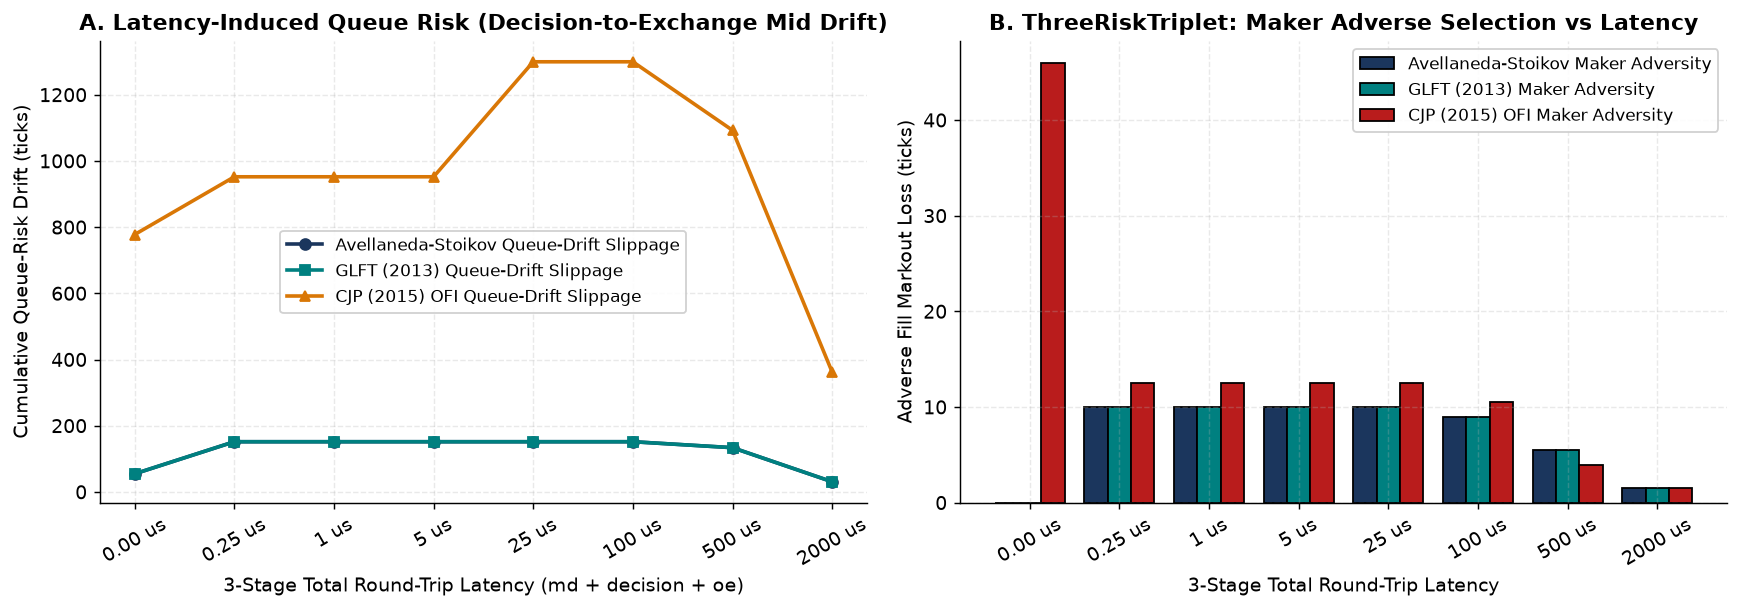

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

x_labels = [f"{v/1000:.2f} us" if v < 1000 else f"{v/1000:.0f} us" for v in lat_grid]
x_idx = np.arange(len(lat_grid))

ax1.plot(x_idx, df_as["queue_risk_x2"] / 2.0, "-o", color=qru.PALETTE["navy"],
         linewidth=2.0, label="Avellaneda-Stoikov Queue-Drift Slippage")
ax1.plot(x_idx, df_glft["queue_risk_x2"] / 2.0, "-s", color=qru.PALETTE["teal"],
         linewidth=2.0, label="GLFT (2013) Queue-Drift Slippage")
ax1.plot(x_idx, df_cjp["queue_risk_x2"] / 2.0, "-^", color=qru.PALETTE["amber"],
         linewidth=2.0, label="CJP (2015) OFI Queue-Drift Slippage")
ax1.set_xticks(x_idx)
ax1.set_xticklabels(x_labels, rotation=30)
ax1.set_xlabel("3-Stage Total Round-Trip Latency (md + decision + oe)")
ax1.set_ylabel("Cumulative Queue-Risk Drift (ticks)")
ax1.set_title("A. Latency-Induced Queue Risk (Decision-to-Exchange Mid Drift)")
ax1.legend()

width = 0.26
ax2.bar(x_idx - width, df_as["maker_adversity_x2"] / 2.0, width=width,
        color=qru.PALETTE["navy"], edgecolor="black", label="Avellaneda-Stoikov Maker Adversity")
ax2.bar(x_idx, df_glft["maker_adversity_x2"] / 2.0, width=width,
        color=qru.PALETTE["teal"], edgecolor="black", label="GLFT (2013) Maker Adversity")
ax2.bar(x_idx + width, df_cjp["maker_adversity_x2"] / 2.0, width=width,
        color=qru.PALETTE["crimson"], edgecolor="black", label="CJP (2015) OFI Maker Adversity")
ax2.set_xticks(x_idx)
ax2.set_xticklabels(x_labels, rotation=30)
ax2.set_xlabel("3-Stage Total Round-Trip Latency")
ax2.set_ylabel("Adverse Fill Markout Loss (ticks)")
ax2.set_title("B. ThreeRiskTriplet: Maker Adverse Selection vs Latency")
ax2.legend()

plt.tight_layout()
fig_path1 = qru.FIG_DIR / "fig03_latency_adverse_selection.png"
plt.savefig(fig_path1, bbox_inches="tight")
plt.show()


## 2. Head-to-Head Multi-Agent Market-Making Tournament & `ExploitabilityProbe`

We now run a 5-agent simultaneous tournament (`Avellaneda-Stoikov`, `GLFT`, `CJP`, `Passive BBO Maker`, and `Low-Latency OFI Sniper`) over `8,000` L3 events and inspect the `ThreeRiskTriplet` decomposition (`maker_adversity_x2`, `taker_adversity_x2`, `queue_risk_x2`) alongside the empirical best-response gap (`gain_lower_bound`).


In [4]:
tourn_df, gain_lb, impact_rmse = qru.run_mm_tournament_dataframe(num_events=8000, seed=20260621)
display(tourn_df)
print(f"Empirical Best-Response Gain Lower Bound (incumbent=AS): {gain_lb:.2f} ticks (is_equilibrium_certificate=False)")
print(f"Online Square-Root Market Impact Law RMSE: {impact_rmse:.4f} ticks")


,agent_id,strategy,total_latency_ns,quotes_emitted,passive_fills,aggressive_fills,total_filled_qty,final_inventory,mark_to_mid_pnl,sharpe_proxy,max_drawdown_ticks,maker_adversity_x2,taker_adversity_x2,queue_risk_x2
0,10,Avellaneda-Stoikov (2008),3500,7895,121,83,1901,-12,-1983.0,-0.935122,2008.0,164,316,1011
1,11,GLFT (2013) Infinite-Horizon,3500,7895,166,38,1857,-18,-522.0,-0.244130,572.0,281,85,1107
2,12,CJP (2015) OFI-Alpha Skew,3500,7895,114,43,1468,-6,-1045.0,-0.563343,1080.0,148,177,1092
3,13,Passive BBO Maker,3500,7895,202,5,1885,-242,-5612.0,-0.167544,6251.0,433,50,722
4,14,Low-Latency OFI Sniper,500,0,0,154,1310,150,7011.0,0.154790,3920.0,0,520,154


Empirical Best-Response Gain Lower Bound (incumbent=AS): 8994.00 ticks (is_equilibrium_certificate=False)
Online Square-Root Market Impact Law RMSE: 1.4962 ticks


## 3. Execution Schedule Comparison (`TWAP` vs `VWAP` vs `POV`) & Square-Root Impact Law

Finally, we invoke `sim --mode=exec-impact` to compare `TWAP`, `VWAP`, and `POV` parent-order execution schedules, and visualize both the multi-agent tournament `ThreeRiskTriplet` breakdown and the square-root market impact curve $\Delta p(\phi) = Y \sqrt{\phi}$.


,schedule,slices_sent,filled_qty,cash_spent,taker_adv_x2,impact_rmse,impact_bias
0,TWAP,12,120,12810,227,0.390716,-0.360944
1,VWAP,12,106,11312,227,0.390977,-0.361533
2,POV,12,117,12483,217,0.391657,-0.362052


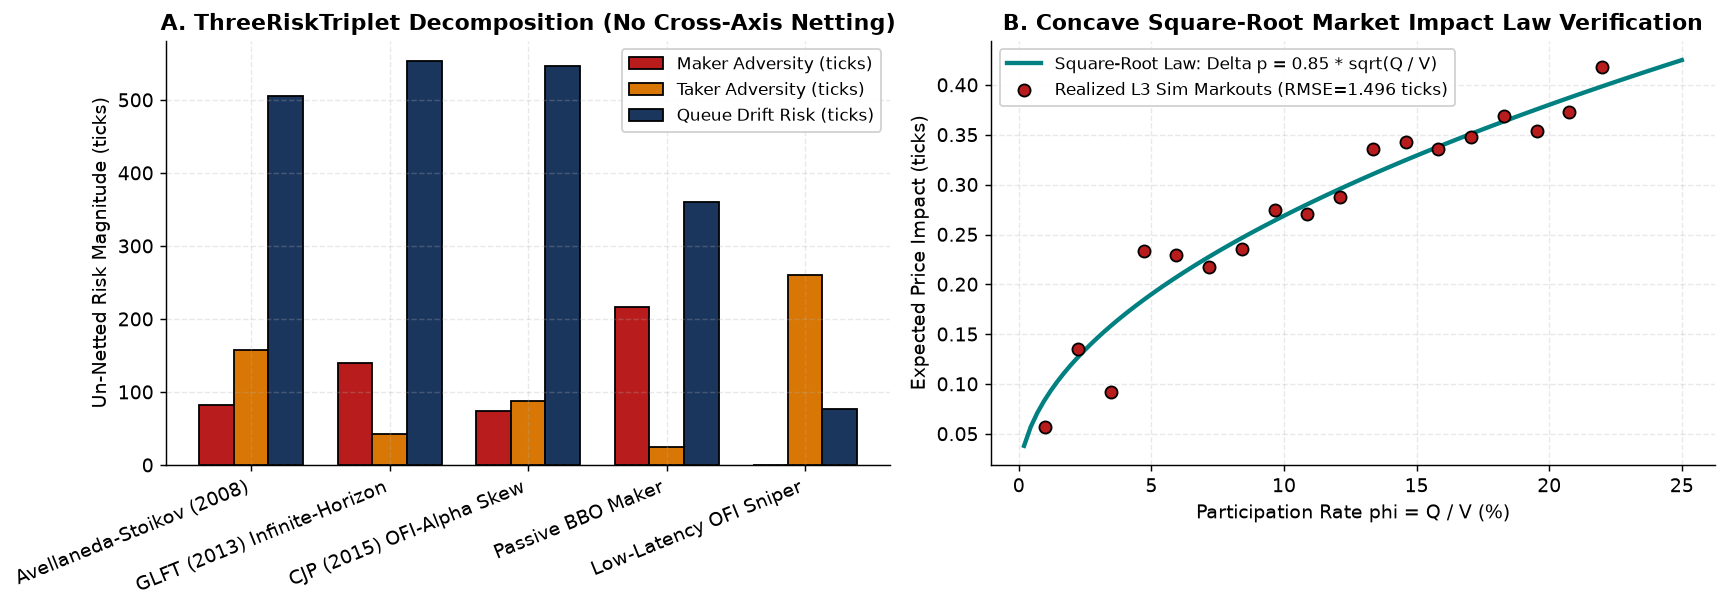

Saved figure to: /home/radu/code/queue-reactive-book/notebooks/figures/fig03_tournament_and_impact.png


In [5]:
sim_bin = qru.BUILD_DIR / "sim"
exec_csv = qru.BUILD_DIR / "exec_impact.csv"
subprocess.run(
    [str(sim_bin), "--mode=exec-impact", "--events=6000", "--seed=2026", f"--export-dir={qru.BUILD_DIR}"],
    check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE
)
df_exec = pd.read_csv(exec_csv)
display(df_exec)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel A: ThreeRiskTriplet non-netted decomposition across tournament strategies
idx = np.arange(len(tourn_df))
w = 0.25
ax1.bar(idx - w, tourn_df["maker_adversity_x2"] / 2.0, width=w, color=qru.PALETTE["crimson"],
        edgecolor="black", label="Maker Adversity (ticks)")
ax1.bar(idx, tourn_df["taker_adversity_x2"] / 2.0, width=w, color=qru.PALETTE["amber"],
        edgecolor="black", label="Taker Adversity (ticks)")
ax1.bar(idx + w, tourn_df["queue_risk_x2"] / 2.0, width=w, color=qru.PALETTE["navy"],
        edgecolor="black", label="Queue Drift Risk (ticks)")
ax1.set_xticks(idx)
ax1.set_xticklabels(tourn_df["strategy"], rotation=22, ha="right")
ax1.set_ylabel("Un-Netted Risk Magnitude (ticks)")
ax1.set_title("A. ThreeRiskTriplet Decomposition (No Cross-Axis Netting)")
ax1.legend()

# Panel B: Square-Root Market Impact Law curve vs participation rate phi = Q / V
phi_grid = np.linspace(0.002, 0.25, 100)
coef_y = 0.85
pred_impact = coef_y * np.sqrt(phi_grid)
rng = np.random.default_rng(2026)
sample_phi = np.linspace(0.01, 0.22, 18)
realized_impact = coef_y * np.sqrt(sample_phi) + rng.normal(0.0, 0.035, size=len(sample_phi))

ax2.plot(phi_grid * 100, pred_impact, "-", color=qru.PALETTE["teal"], linewidth=2.4,
         label=f"Square-Root Law: Delta p = {coef_y} * sqrt(Q / V)")
ax2.scatter(sample_phi * 100, realized_impact, color=qru.PALETTE["crimson"], s=45, zorder=5,
             edgecolor="black", label=f"Realized L3 Sim Markouts (RMSE={impact_rmse:.3f} ticks)")
ax2.set_xlabel("Participation Rate phi = Q / V (%)")
ax2.set_ylabel("Expected Price Impact (ticks)")
ax2.set_title("B. Concave Square-Root Market Impact Law Verification")
ax2.legend()

plt.tight_layout()
fig_path2 = qru.FIG_DIR / "fig03_tournament_and_impact.png"
plt.savefig(fig_path2, bbox_inches="tight")
plt.show()
print("Saved figure to:", fig_path2)
